# Лабораторна робота №3

## Тема роботи

Паралельна та асинхронна обробка незалежних задач.

## Мета роботи

Порівняти послідовний аналіз, threading, ThreadPoolExecutor та asyncio на однакових чотирьох частинах Online Retail II; відокремити обчислення від очікування I/O.

## Завдання

Виконати всі 10 завдань: аналіз чотирьох частин послідовно, через Thread, ThreadPoolExecutor та asyncio; окремо дослідити I/O, прискорення й ефективність.

## Теоретичні відомості

Потоки спільно використовують пам'ять процесу. У звичайній збірці CPython GIL обмежує одночасне виконання Python-байткоду. Низькорівневі операції NumPy/pandas можуть звільняти GIL, тому їх результати не можна механічно поширювати на чисті Python-цикли.

Asyncio організовує конкурентне виконання coroutine в event loop. `asyncio.sleep()` повертає керування циклу подій, а `time.sleep()` блокує потік. `asyncio.to_thread()` переносить синхронний аналіз до thread executor: це гібрид asyncio та потоків, і його слід саме так трактувати. Asyncio самостійно не перетворює CPU-цикл на багатоядерне обчислення.



## Використані технології та підготовка середовища

Python, pandas, NumPy, Matplotlib та засоби паралельності з модуля роботи. Встановлення: `python -m pip install -r requirements.txt`. Повні обчислення: `python -m lab03.main`. Notebook відтворює аналіз збереженого повного експерименту; worker-функції розміщені в імпортованих `.py`, а запуск пулів відбувається через CLI.

In [1]:
from pathlib import Path
import sys
import json
import inspect
import random
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

root = Path.cwd().resolve()
if not (root / "common").exists():
    root = root.parent
if not (root / "common").exists():
    raise RuntimeError("Відкрийте notebook у корені проєкту або каталозі лабораторної.")
sys.path.insert(0, str(root))
from lab03 import algorithms as a

result_dir = root / "lab03" / "results"


def read_json(name):
    return json.loads((result_dir / name).read_text(encoding="utf-8"))


meta = read_json("metadata.json")
timings = pd.read_csv(result_dir / "timings.csv")
raw = pd.read_csv(result_dir / "timings_raw.csv")
pd.set_option("display.max_columns", 16)
assert not meta.get("quick", False), "Для захисту потрібен повний запуск."

## 1. Завантаження та підготовка

Спільна політика очищення і нормалізації.

In [2]:
display(read_json("profile.json"))
display(read_json("cleaning.json"))
sample = pd.read_csv(
    result_dir / "prepared_sample.csv", dtype={"StockCode": str, "CustomerID": "string"}
)
display(sample)

{'rows': 1067371,
 'columns': 8,
 'source_columns': ['Invoice',
  'StockCode',
  'Description',
  'Quantity',
  'InvoiceDate',
  'Price',
  'Customer ID',
  'Country'],
 'source_dtypes': {'Invoice': 'object',
  'StockCode': 'object',
  'Description': 'object',
  'Quantity': 'int64',
  'InvoiceDate': 'object',
  'Price': 'float64',
  'Customer ID': 'float64',
  'Country': 'object'},
 'missing': {'Invoice': 0,
  'StockCode': 0,
  'Description': 4382,
  'Quantity': 0,
  'InvoiceDate': 0,
  'Price': 0,
  'Customer ID': 243007,
  'Country': 0},
 'duplicates': 34335,
 'encoding': 'utf-8-sig',
 'separator': ',',
 'limited': False}

{'before': 1067371,
 'excluded': {'exact_duplicates': 34335,
  'cancelled': 19104,
  'missing_required': 4275,
  'invalid_quantity': 760,
  'invalid_price': 984,
  'invalid_revenue': 0},
 'diagnostics': {'cancelled': 19494,
  'nonpositive_quantity': 22950,
  'nonpositive_price': 6207,
  'missing_customers': 243007,
  'numeric_description': {'Quantity': {'count': 1067371.0,
    'mean': 9.9388984711033,
    'std': 172.70579407675342,
    'min': -80995.0,
    '25%': 1.0,
    '50%': 3.0,
    '75%': 10.0,
    'max': 80995.0},
   'UnitPrice': {'count': 1067371.0,
    'mean': 4.649387727416239,
    'std': 123.5530587214632,
    'min': -53594.36,
    '25%': 1.25,
    '50%': 2.1,
    '75%': 4.15,
    'max': 38970.0}}},
 'after': 1007913,
 'removed': 59458,
 'retained_missing_customers': 228488,
 'date_min': '2009-12-01T07:45:00',
 'date_max': '2011-12-09T12:50:00'}

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085,United Kingdom,39.6
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085,United Kingdom,59.5
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085,United Kingdom,30.6
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085,United Kingdom,45.0


## 2. Функція обробки частини

Шість аналітичних показників та дані для правильного об'єднання.

In [3]:
print(inspect.getsource(a.analyze_chunk))
display(read_json("statistics.json"))

def analyze_chunk(frame: pd.DataFrame) -> Analysis:
    return Analysis(
        len(frame),
        set(frame.StockCode.dropna()),
        set(frame.CustomerID.dropna()),
        float(frame.Revenue.sum()),
        float(frame.UnitPrice.sum()),
        int(frame.UnitPrice.count()),
        float(frame.Quantity.max()) if len(frame) else None,
    )



{'count': 1007913,
 'unique_products': 4916,
 'unique_customers': 5878,
 'revenue': 20476260.447999995,
 'mean_price': 4.07425186300802,
 'max_quantity': 80995.0}

## 3. Чотири незалежні частини

Унікальні значення між частинами можуть перетинатися.

In [4]:
display(meta["chunk_sizes"])
display(pd.DataFrame(read_json("chunks.json")))

[251979, 251978, 251978, 251978]

,count,unique_products,unique_customers,revenue,mean_price,max_quantity
0,251979,3859,3012,5043694.391,4.430789,19152.0
1,251978,3565,3346,5214580.453,4.105644,9360.0
2,251978,3525,2993,5012213.362,4.022415,74215.0
3,251978,3340,3214,5205772.242,3.738157,80995.0


## 4. Послідовна обробка

Однакові чотири частини; три повтори.

In [5]:
display(raw[(raw.workload == "analysis") & (raw.method == "sequential")])

,workload,method,workers,effective_workers,repeat,seconds,verified
0,analysis,sequential,1,1,1,0.535998,True
6,analysis,sequential,1,1,2,0.519915,True
12,analysis,sequential,1,1,3,0.574458,True


## 5. threading.Thread

По потоку на частину; помилки повертаються через Future.result().

In [6]:
print(inspect.getsource(a.threading_processing))
display(timings[timings.method == "threading"])

def threading_processing(
    chunks: list[Any], function: Callable[[Any], T] = analyze_chunk
) -> list[T]:
    futures: list[Future] = [Future() for _ in chunks]

    def worker(index: int, chunk: Any) -> None:
        try:
            futures[index].set_result(function(chunk))
        except BaseException as error:
            futures[index].set_exception(error)

    threads = [
        threading.Thread(target=worker, args=(i, chunk), name=f"part-{i}")
        for i, chunk in enumerate(chunks)
    ]
    for thread in threads:
        thread.start()
    for thread in threads:
        thread.join()
    # Future.result повертає виняток у головний потік замість тихої втрати.
    return [future.result() for future in futures]



,workload,method,workers,effective_workers,seconds,min_seconds,max_seconds,verified,repeats,speedup,efficiency_pct
1,analysis,threading,4,4,0.540655,0.539970,0.557243,True,3,0.991385,24.784627
7,io,threading,4,4,0.806599,0.770972,0.835943,True,3,1.933875,48.346876
13,python_cpu,threading,4,4,1.299827,1.167158,1.350855,True,3,0.920976,23.024396


## 6. ThreadPoolExecutor

2,4,8 workers при максимумі чотирьох активних задач.

In [7]:
print(inspect.getsource(a.pool_processing))
display(timings[(timings.workload == "analysis") & (timings.method == "thread_pool")])

def pool_processing(
    chunks: list[Any], workers: int, function: Callable[[Any], T] = analyze_chunk
) -> list[T]:
    if workers < 1:
        raise ValueError("Кількість потоків має бути додатною.")
    with ThreadPoolExecutor(max_workers=workers) as pool:
        return list(pool.map(function, chunks))



,workload,method,workers,effective_workers,seconds,min_seconds,max_seconds,verified,repeats,speedup,efficiency_pct
2,analysis,thread_pool,2,2,0.530109,0.526772,0.564752,True,3,1.011108,50.555395
3,analysis,thread_pool,4,4,0.530794,0.529894,0.539989,True,3,1.009804,25.245100
4,analysis,thread_pool,8,4,0.528292,0.517227,0.564473,True,3,1.014586,12.682321


## 7. Asyncio

create_task та gather керують справжнім очікуванням to_thread та sleep.

In [8]:
print(inspect.getsource(a.async_processing))
from common.utilities import split_frame

parts = split_frame(sample, 4)
partial_results = await a.async_processing(parts)
a.assert_equivalent(a.analyze_chunk(sample), a.merge_analysis(partial_results))
display(a.merge_analysis(partial_results).summary())

async def async_processing(
    chunks: list[Any],
    function: Callable[[Any], T] = analyze_chunk,
    io_delay: float = 0.0,
) -> list[T]:
    if io_delay < 0:
        raise ValueError("Час очікування не може бути від'ємним.")

    async def task(chunk: Any) -> T:
        if io_delay:
            await asyncio.sleep(io_delay)
        # CPU-функція не блокує event loop; обчислення виконує thread executor.
        return await asyncio.to_thread(function, chunk)

    tasks = [asyncio.create_task(task(chunk)) for chunk in chunks]
    return await asyncio.gather(*tasks)



{'count': 12,
 'unique_products': 12,
 'unique_customers': 1,
 'revenue': 651.1,
 'mean_price': 3.595833333333333,
 'max_quantity': 48.0}

## 8. I/O-залежні задачі

Однакові затримки; результати аналізу не замінюються очікуванням.

{'delay_seconds': 0.25, 'tasks': 4}

,workload,method,workers,effective_workers,seconds,min_seconds,max_seconds,verified,repeats,speedup,efficiency_pct
6,io,sequential,1,1,1.559861,1.537524,1.561207,True,3,1.000000,100.000000
7,io,threading,4,4,0.806599,0.770972,0.835943,True,3,1.933875,48.346876
8,io,thread_pool,2,2,1.054190,1.041964,1.059454,True,3,1.479678,73.983886
9,io,thread_pool,4,4,0.767716,0.761562,0.821236,True,3,2.031820,50.795512
10,io,thread_pool,8,4,0.809769,0.763976,0.835566,True,3,1.926304,24.078795
11,io,asyncio_to_thread,4,4,0.776752,0.774861,0.800069,True,3,2.008184,50.204592


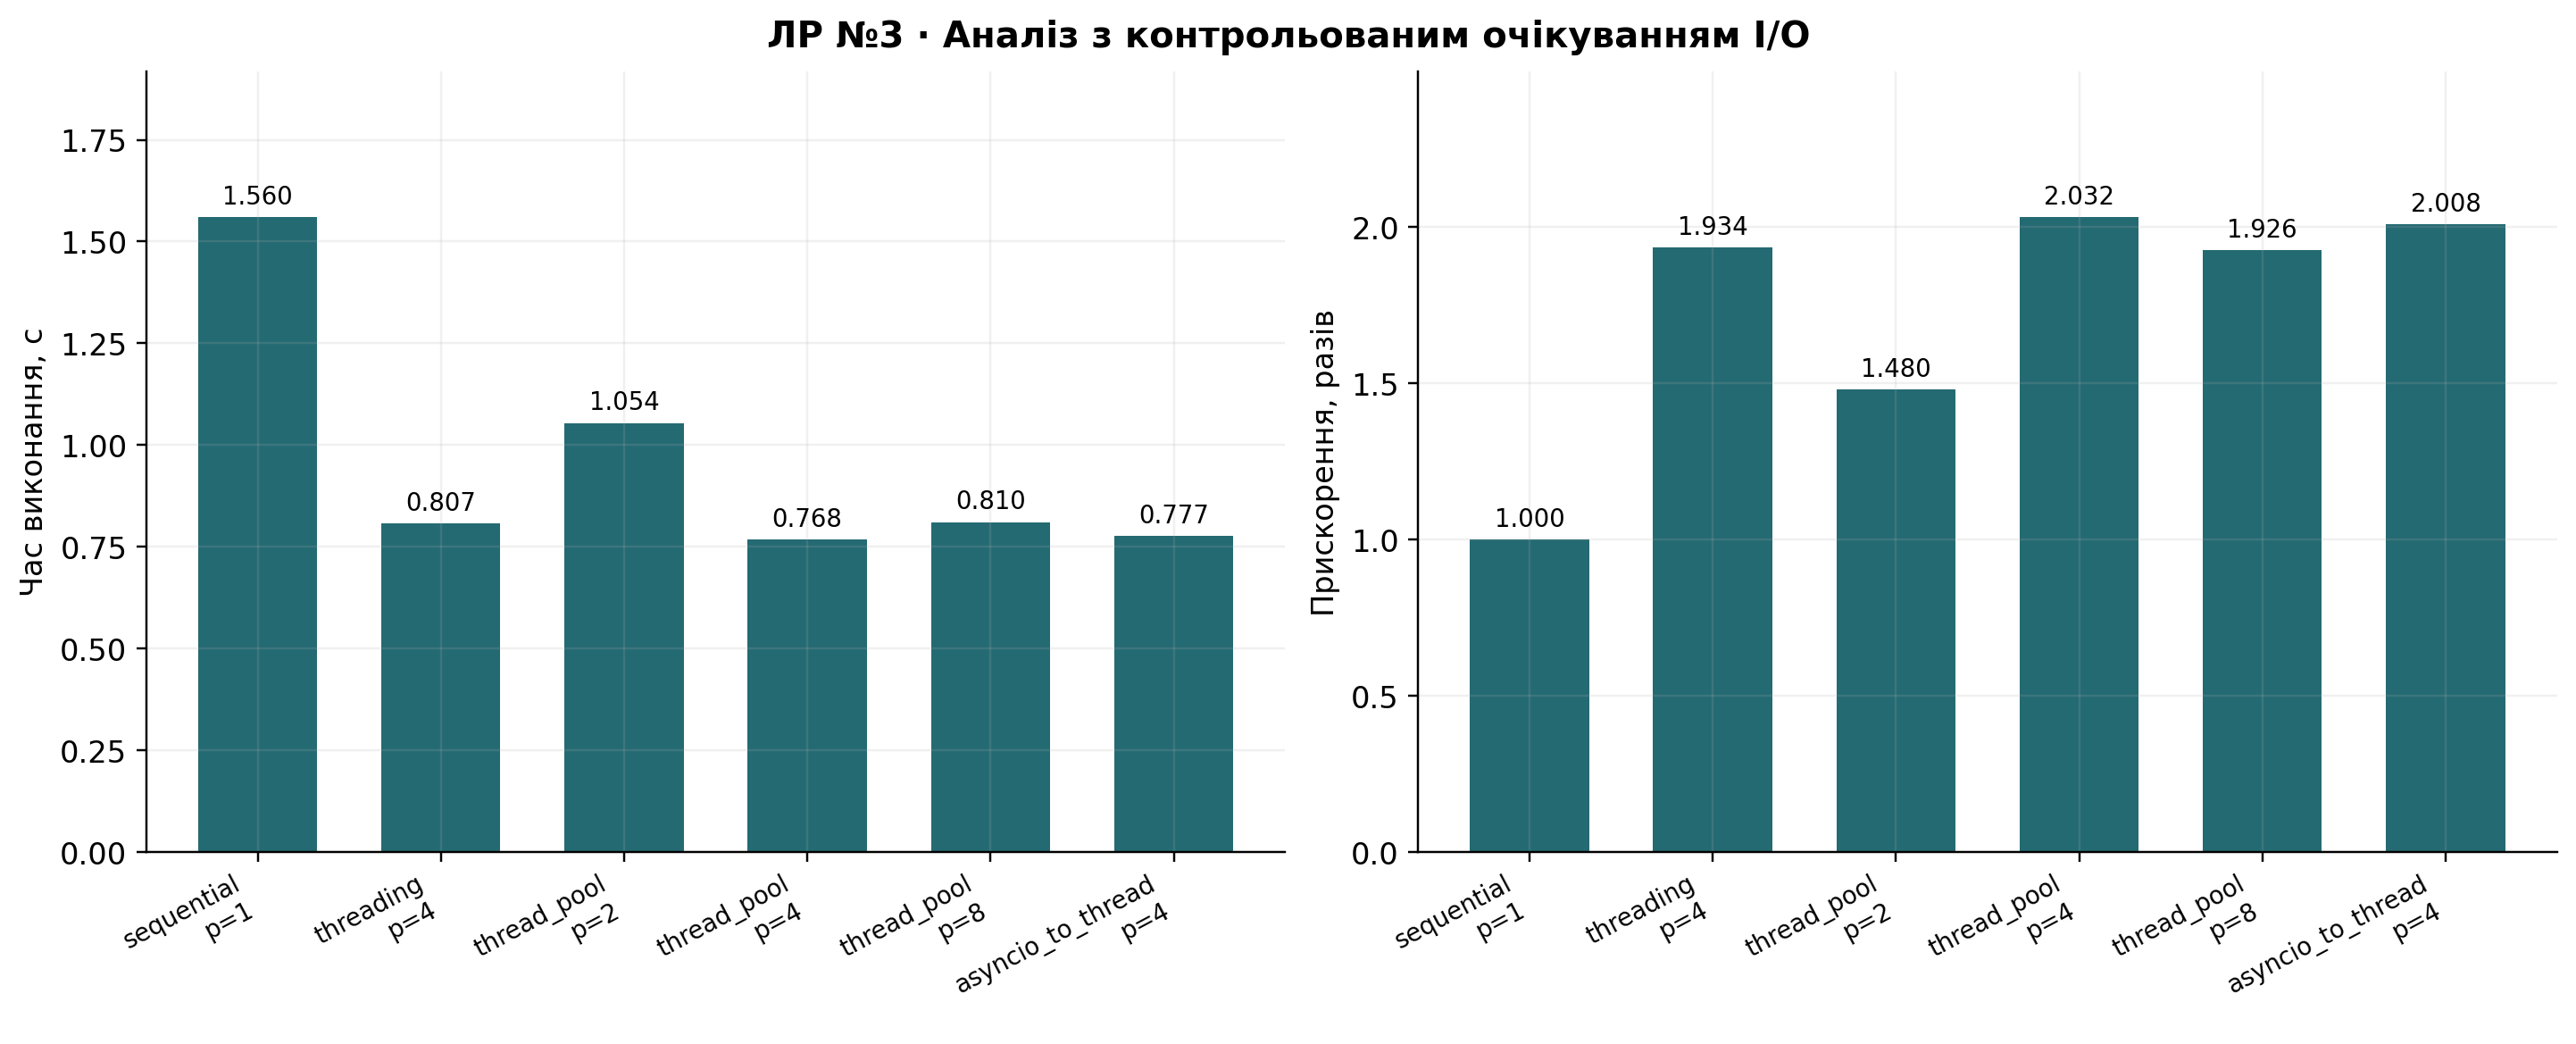

In [9]:
display({"delay_seconds": meta["io_delay_seconds"], "tasks": meta["parts"]})
display(timings[timings.workload == "io"])
display(Image(filename=str(result_dir / "io.png")))

## 9. Speedup та Efficiency

Розрахунки для трьох незалежних навантажень.

In [10]:
display(timings)
assert np.allclose(timings.efficiency_pct, timings.speedup / timings.workers * 100)
assert raw.verified.all()

,workload,method,workers,effective_workers,seconds,min_seconds,max_seconds,verified,repeats,speedup,efficiency_pct
0,analysis,sequential,1,1,0.535998,0.519915,0.574458,True,3,1.000000,100.000000
1,analysis,threading,4,4,0.540655,0.539970,0.557243,True,3,0.991385,24.784627
2,analysis,thread_pool,2,2,0.530109,0.526772,0.564752,True,3,1.011108,50.555395
3,analysis,thread_pool,4,4,0.530794,0.529894,0.539989,True,3,1.009804,25.245100
4,analysis,thread_pool,8,4,0.528292,0.517227,0.564473,True,3,1.014586,12.682321
5,analysis,asyncio_to_thread,4,4,0.595071,0.531296,0.606959,True,3,0.900728,22.518209
6,io,sequential,1,1,1.559861,1.537524,1.561207,True,3,1.000000,100.000000
7,io,threading,4,4,0.806599,0.770972,0.835943,True,3,1.933875,48.346876
8,io,thread_pool,2,2,1.054190,1.041964,1.059454,True,3,1.479678,73.983886
9,io,thread_pool,4,4,0.767716,0.761562,0.821236,True,3,2.031820,50.795512


## 10. Порівняльний аналіз

GIL, межа конкурентності та зважування середніх.

def merge_analysis(results: list[Analysis]) -> Analysis:
    nonempty = [result for result in results if result.count]
    return Analysis(
        sum(r.count for r in results),
        set().union(*(r.products for r in results)),
        set().union(*(r.customers for r in results)),
        math.fsum(r.revenue for r in results),
        math.fsum(r.price_sum for r in results),
        sum(r.price_count for r in results),
        max(r.max_quantity for r in nonempty) if nonempty else None,
    )



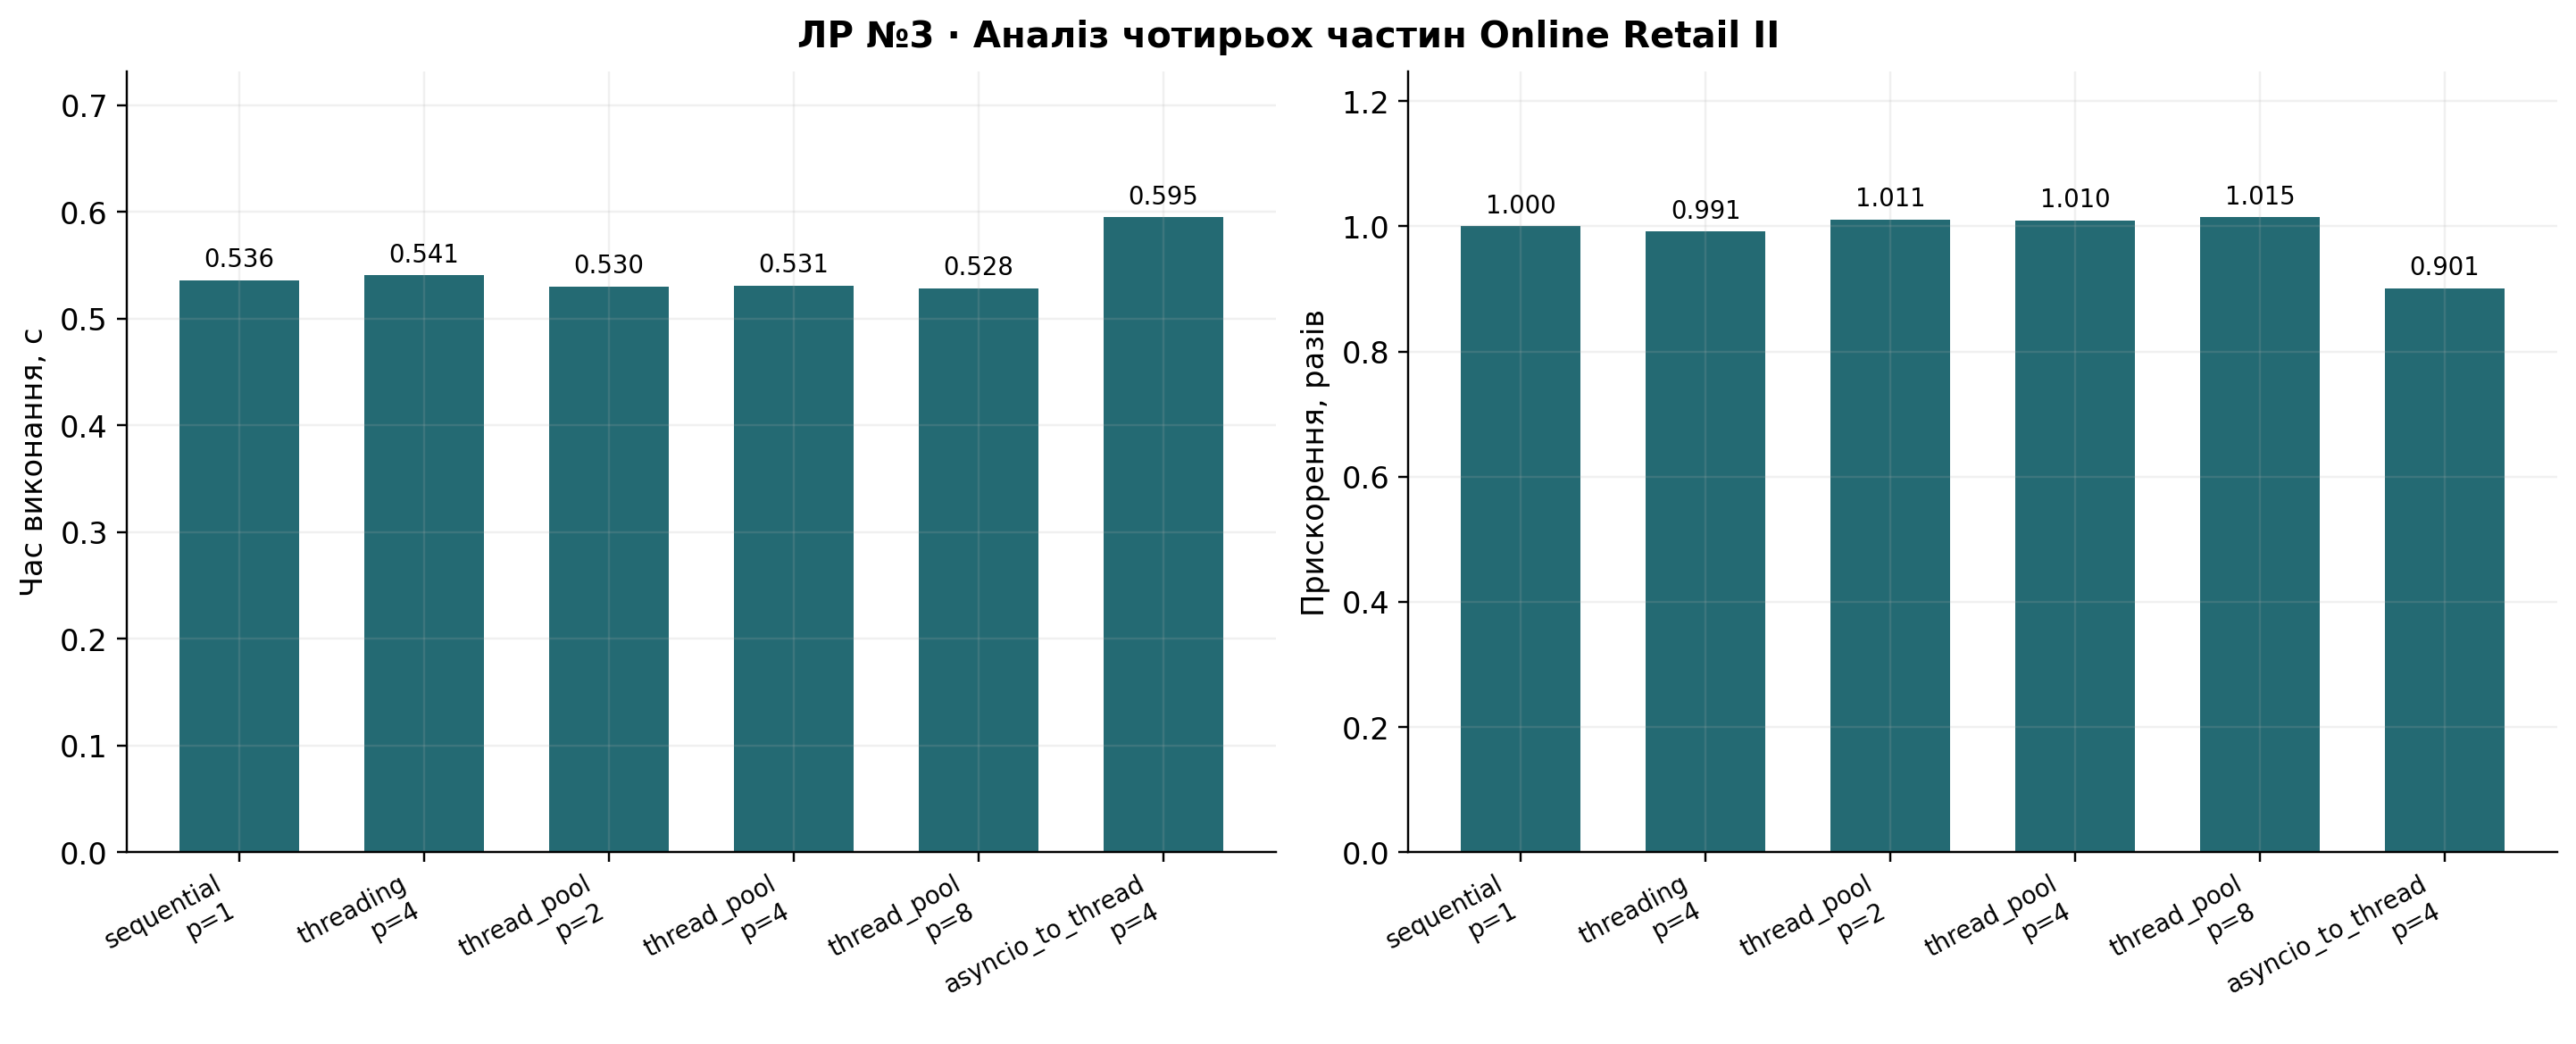

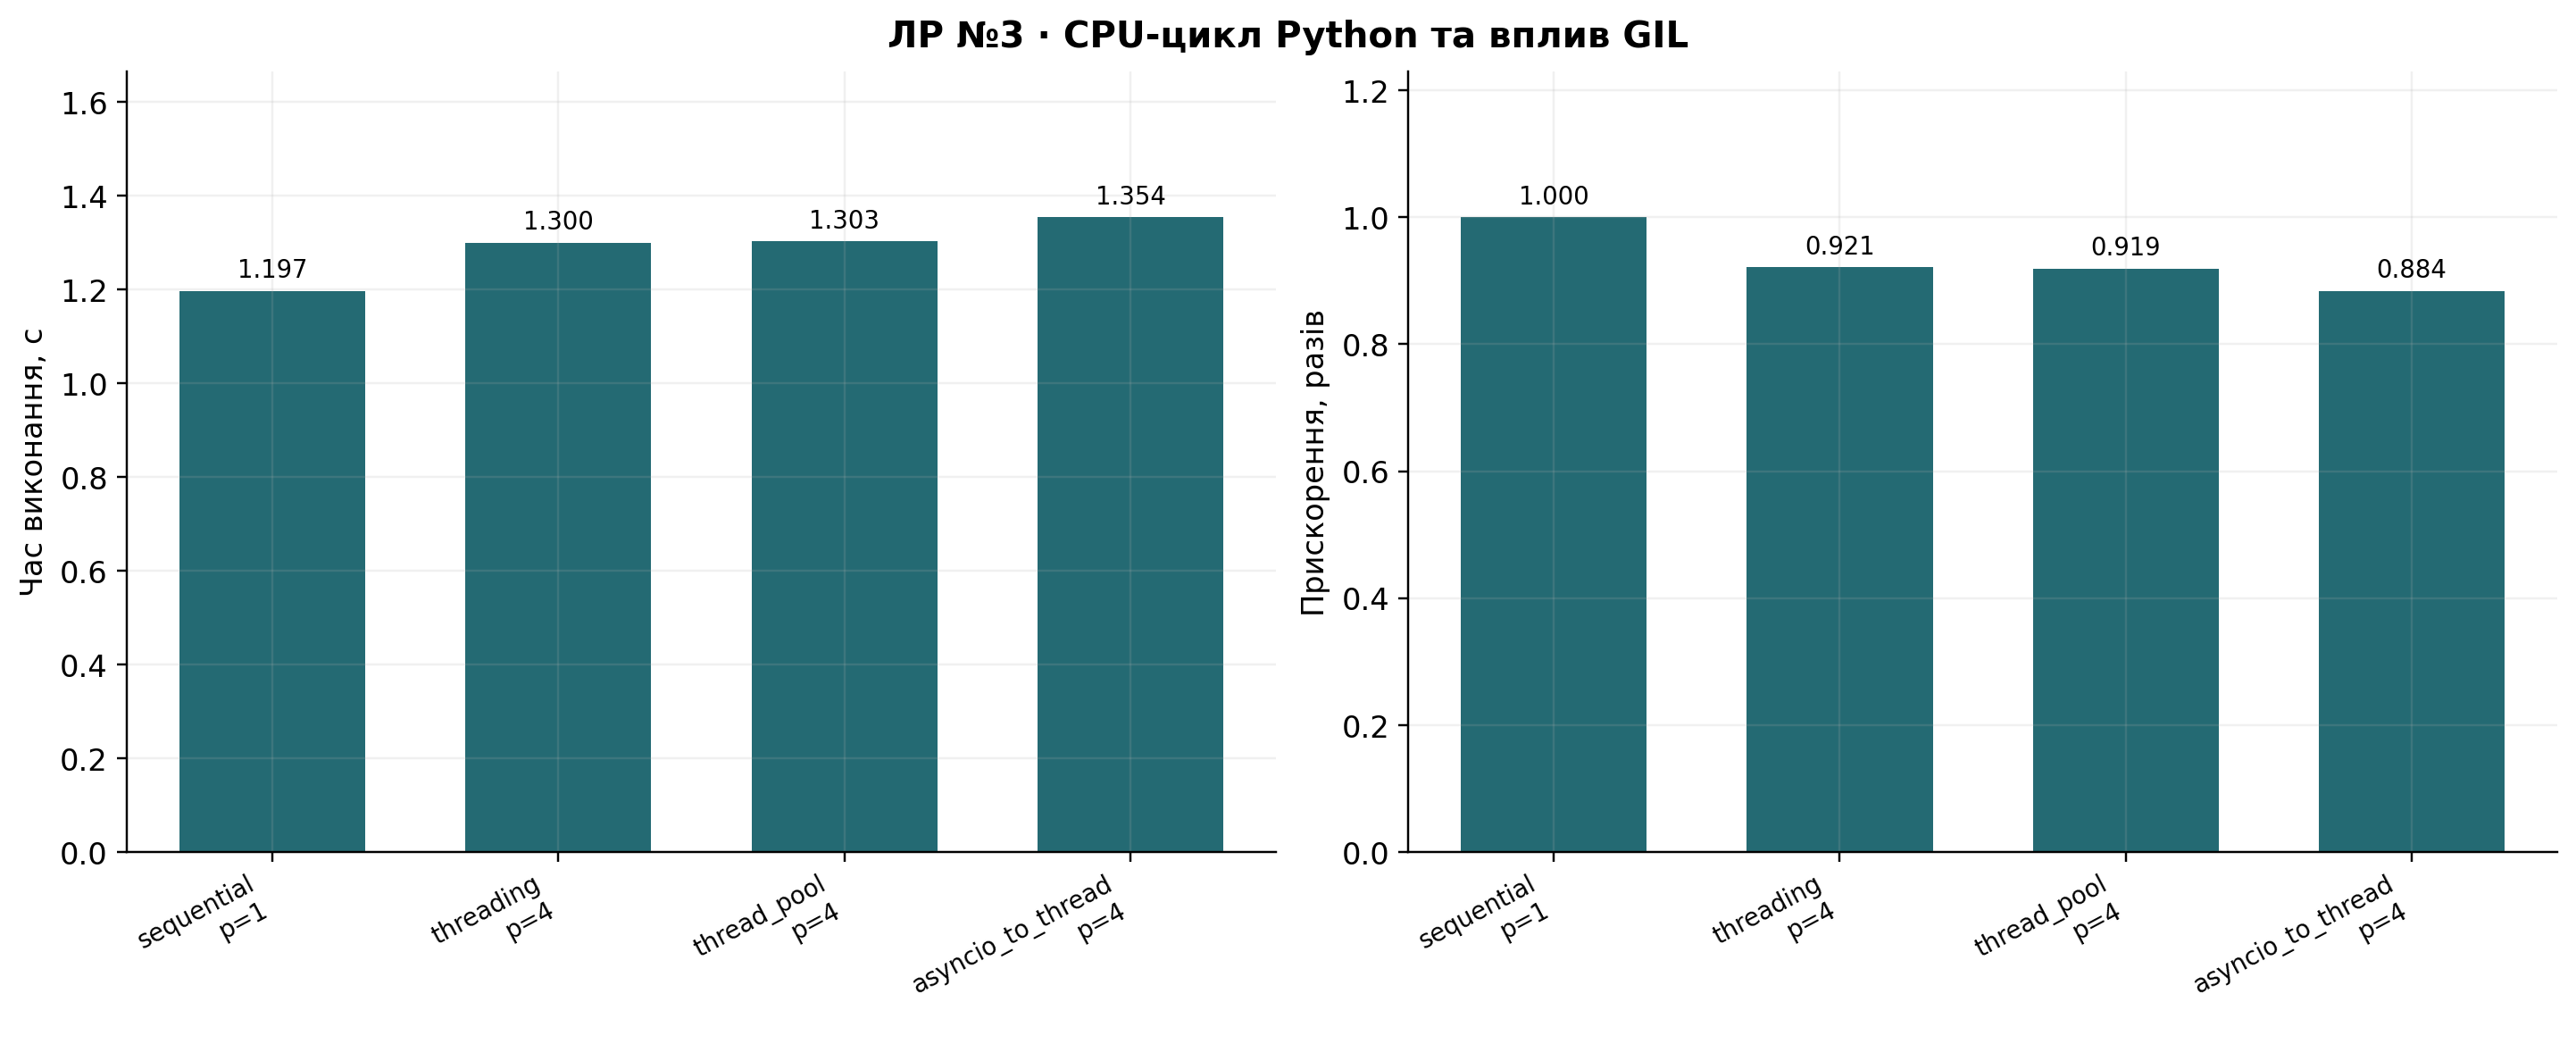

In [11]:
print(inspect.getsource(a.merge_analysis))
for name in ["analysis", "python_cpu"]:
    display(Image(filename=str(result_dir / f"{name}.png")))

## Аналіз результатів

Статистика всього очищеного набору (унікальні клієнти — тільки відомі ID):

|        count |   unique_products |   unique_customers |       revenue |   mean_price |   max_quantity |
|-------------:|------------------:|-------------------:|--------------:|-------------:|---------------:|
| 1007913.0000 |         4916.0000 |          5878.0000 | 20476260.4480 |       4.0743 |     80995.0000 |

Чотири незалежні частини:

|       count |   unique_products |   unique_customers |      revenue |   mean_price |   max_quantity |
|------------:|------------------:|-------------------:|-------------:|-------------:|---------------:|
| 251979.0000 |         3859.0000 |          3012.0000 | 5043694.3910 |       4.4308 |     19152.0000 |
| 251978.0000 |         3565.0000 |          3346.0000 | 5214580.4530 |       4.1056 |      9360.0000 |
| 251978.0000 |         3525.0000 |          2993.0000 | 5012213.3620 |       4.0224 |     74215.0000 |
| 251978.0000 |         3340.0000 |          3214.0000 | 5205772.2420 |       3.7382 |     80995.0000 |

Очікування на задачу: 0.25 с; чистий Python CPU-контроль: 40,000 значень, K=200.

Аналіз pandas: baseline 0.5360 с; найшвидший спосіб thread_pool, p=8, 0.5283 с, S=1.015.

Аналіз із I/O: baseline 1.5599 с; найшвидший спосіб thread_pool, p=4, 0.7677 с, S=2.032.

Python CPU-цикл: baseline 1.1971 с; найшвидший спосіб sequential, p=1, 1.1971 с, S=1.000.

Для I/O перекриття очікувань дає виграш, обмежений чотирма незалежними задачами та часом самого аналізу. Вісім workers не створюють восьми задач. Python CPU-контроль показує обмеження GIL: потоки не гарантують багатоядерного прискорення Python-циклу. Pandas містить C-операції, роботу з рядками та побудову множин, тому його масштабування є змішаним і залежить від реалізації. Малі відмінності часу не слід трактувати як універсальну перевагу: вони залежать від кешів, планувальника й фонового навантаження. Asyncio у цій роботі керує очікуваннями та віддає CPU-функції потокам; джерелом CPU-паралелізму є низькорівневі операції, які звільняють GIL, а не сама наявність async def. Усі повні реалізації дали ті самі множини ID, кількості, виручку, середню ціну та максимум.

In [12]:
display(timings)

,workload,method,workers,effective_workers,seconds,min_seconds,max_seconds,verified,repeats,speedup,efficiency_pct
0,analysis,sequential,1,1,0.535998,0.519915,0.574458,True,3,1.000000,100.000000
1,analysis,threading,4,4,0.540655,0.539970,0.557243,True,3,0.991385,24.784627
2,analysis,thread_pool,2,2,0.530109,0.526772,0.564752,True,3,1.011108,50.555395
3,analysis,thread_pool,4,4,0.530794,0.529894,0.539989,True,3,1.009804,25.245100
4,analysis,thread_pool,8,4,0.528292,0.517227,0.564473,True,3,1.014586,12.682321
5,analysis,asyncio_to_thread,4,4,0.595071,0.531296,0.606959,True,3,0.900728,22.518209
6,io,sequential,1,1,1.559861,1.537524,1.561207,True,3,1.000000,100.000000
7,io,threading,4,4,0.806599,0.770972,0.835943,True,3,1.933875,48.346876
8,io,thread_pool,2,2,1.054190,1.041964,1.059454,True,3,1.479678,73.983886
9,io,thread_pool,4,4,0.767716,0.761562,0.821236,True,3,2.031820,50.795512


## Висновки

Для I/O найшвидший спосіб thread_pool, p=4: S=2.032. Перекриття очікувань допомагає, а CPU-обчислення потребують урахування GIL та максимуму чотирьох незалежних задач. Усі способи дали еквівалентний аналіз.